<a href="https://colab.research.google.com/github/MukeshRegar91/Integrated-Retail-Analytics-for-Store-Optimization/blob/main/Capstone_Anomaly_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2: Anomaly Detection in Sales Data
**Integrated Retail Analytics for Store Optimization - Capstone**

**Objective:** Identify unusual sales patterns across stores and departments, distinguish expected causes (holidays, markdowns) from genuine anomalies, and flag them for further investigation / data quality handling.

In [5]:
# from google.colab import drive
# drive.mount('/content/drive')

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

## 1. Load the cleaned dataset
Using the merged, cleaned dataset produced in the EDA phase (`merged_walmart_data.csv`).

In [7]:
df = pd.read_csv(r"/content/drive/MyDrive/Integrated Retail Analytics for Store Optimization/Captsone EDA/Final_merged_dataset.csv", parse_dates=['Date'])
df = df.sort_values(['Store', 'Dept', 'Date']).reset_index(drop=True)
print(df.shape)
df[['Store','Dept','Date','Weekly_Sales','IsHoliday']].head()

(421570, 23)


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


## 2. Why per-store-department, not global?
A single global threshold (e.g. "anything above $50,000 is unusual") doesn't work here - a small electronics department in a small store and a large grocery department in a flagship store have completely different normal ranges. So every store-department combination is checked **against its own history**, the same way you'd flag an unusual electricity bill by comparing it to *your own* past bills, not your neighbour's.

In [8]:
df.groupby(['Store','Dept']).size().describe()

,0
count,3331.000000
mean,126.559592
std,40.212763
min,1.000000
25%,143.000000
50%,143.000000
75%,143.000000
max,143.000000


## 3. Method A - IQR (Interquartile Range) rule, per Store-Dept
For each store-department's own sales history, anything below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR` is flagged as statistically unusual. This is the same rule used to draw the whiskers on a box plot.

In [9]:
def iqr_flags(group):
    q1, q3 = group['Weekly_Sales'].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (group['Weekly_Sales'] < lower) | (group['Weekly_Sales'] > upper)

df['Anomaly_IQR'] = df.groupby(['Store', 'Dept'], group_keys=False).apply(iqr_flags)

print(f"IQR-flagged anomalies: {df['Anomaly_IQR'].sum()} rows ({df['Anomaly_IQR'].mean():.2%} of all rows)")

IQR-flagged anomalies: 18056 rows (4.28% of all rows)


### What share of IQR anomalies fall on a holiday week?
If most flagged weeks are holidays, the "anomaly" is really just an expected seasonal spike, not a data problem.

In [10]:
holiday_share_iqr = df.loc[df['Anomaly_IQR'], 'IsHoliday'].mean()
print(f"{holiday_share_iqr:.1%} of IQR-flagged anomalies are holiday weeks")
print(f"=> {1-holiday_share_iqr:.1%} are NOT holiday weeks - these are the ones worth investigating further")

16.4% of IQR-flagged anomalies are holiday weeks
=> 83.6% are NOT holiday weeks - these are the ones worth investigating further


## 4. Method B - Isolation Forest
Isolation Forest is an ML model built specifically to find outliers: it randomly splits the data repeatedly, and points that get isolated in very few splits (i.e. they're "easy to separate" from the rest) are flagged as anomalies. Instead of feeding it raw Weekly_Sales (which varies hugely store to store), we feed it **how far each week's sales deviate from that store-dept's own average**, plus whether it was a holiday or markdown week - so the model judges deviation in context, not raw dollar amounts.

In [11]:
df['Sales_vs_DeptStd'] = df.groupby(['Store','Dept'])['Weekly_Sales'].transform(
    lambda s: (s - s.mean()) / (s.std() if s.std() > 0 else 1)
)

iso_features = df[['Sales_vs_DeptStd', 'IsHoliday', 'Has_MarkDown']].copy()
iso_features['IsHoliday'] = iso_features['IsHoliday'].astype(int)

iso_model = IsolationForest(contamination=0.03, random_state=42, n_estimators=200)
df['Anomaly_IsoForest'] = iso_model.fit_predict(iso_features) == -1

print(f"Isolation Forest anomalies: {df['Anomaly_IsoForest'].sum()} rows ({df['Anomaly_IsoForest'].mean():.2%} of all rows)")

Isolation Forest anomalies: 12643 rows (3.00% of all rows)


In [12]:
holiday_share_iso = df.loc[df['Anomaly_IsoForest'], 'IsHoliday'].mean()
print(f"{holiday_share_iso:.1%} of Isolation Forest anomalies are holiday weeks")

71.8% of Isolation Forest anomalies are holiday weeks


## 5. Comparing the two methods

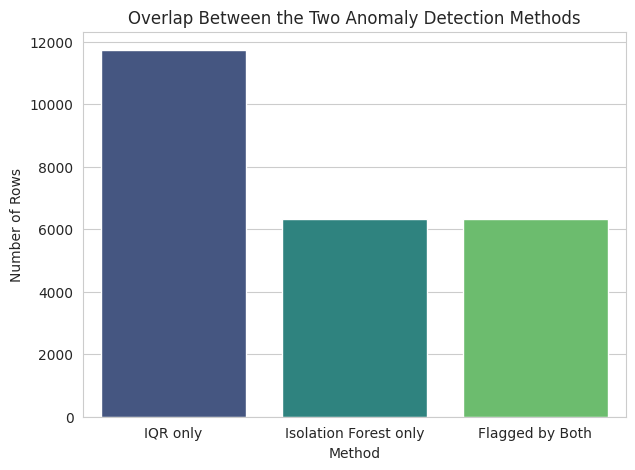

,Method,Count
0,IQR only,11736
1,Isolation Forest only,6323
2,Flagged by Both,6320


In [13]:
both_flagged = (df['Anomaly_IQR'] & df['Anomaly_IsoForest']).sum()
only_iqr = (df['Anomaly_IQR'] & ~df['Anomaly_IsoForest']).sum()
only_iso = (~df['Anomaly_IQR'] & df['Anomaly_IsoForest']).sum()

summary = pd.DataFrame({
    'Method': ['IQR only', 'Isolation Forest only', 'Flagged by Both'],
    'Count': [only_iqr, only_iso, both_flagged]
})
plt.figure(figsize=(7,5))
sns.barplot(data=summary, x='Method', y='Count', palette='viridis')
plt.title('Overlap Between the Two Anomaly Detection Methods')
plt.ylabel('Number of Rows')
plt.show()
summary

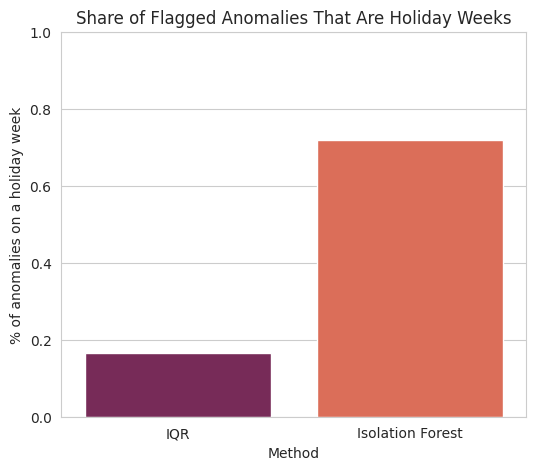

In [14]:
holiday_compare = pd.DataFrame({
    'Method': ['IQR', 'Isolation Forest'],
    'Holiday_Share': [holiday_share_iqr, holiday_share_iso]
})
plt.figure(figsize=(6,5))
sns.barplot(data=holiday_compare, x='Method', y='Holiday_Share', palette='rocket')
plt.title('Share of Flagged Anomalies That Are Holiday Weeks')
plt.ylabel('% of anomalies on a holiday week')
plt.ylim(0,1)
plt.show()

**What this tells us:** the IQR method flags a broader set of statistical outliers (~4.3% of rows), most of which (~84%) are **not** holiday weeks - meaning most IQR outliers are genuine, unexplained anomalies worth a closer look (data entry errors, one-off local events, stock-outs, etc.). The Isolation Forest, despite being given the holiday flag as context, still flags holiday weeks heavily (~72% of its anomalies) - confirming holiday sales spikes are large enough in magnitude to look unusual even to a model that *knows* it's a holiday. In other words: **holiday spikes are expected anomalies (explained), while the non-holiday IQR outliers are the real ones to investigate.**

## 6. Visual check - example store-department with anomalies marked
Picking one store-department combination to see what a flagged anomaly actually looks like on a sales timeline.

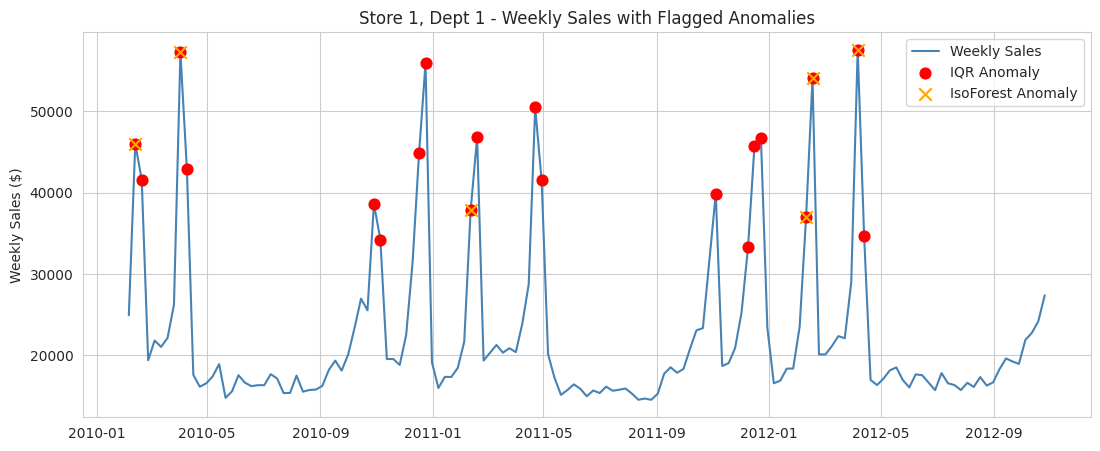

In [15]:
example = df[(df['Store']==1) & (df['Dept']==1)].sort_values('Date')

plt.figure(figsize=(13,5))
plt.plot(example['Date'], example['Weekly_Sales'], color='steelblue', label='Weekly Sales', zorder=1)
plt.scatter(example.loc[example['Anomaly_IQR'],'Date'], example.loc[example['Anomaly_IQR'],'Weekly_Sales'],
            color='red', s=60, label='IQR Anomaly', zorder=2)
plt.scatter(example.loc[example['Anomaly_IsoForest'],'Date'], example.loc[example['Anomaly_IsoForest'],'Weekly_Sales'],
            color='orange', marker='x', s=80, label='IsoForest Anomaly', zorder=3)
plt.title('Store 1, Dept 1 - Weekly Sales with Flagged Anomalies')
plt.ylabel('Weekly Sales ($)')
plt.legend()
plt.show()

## 7. Genuine (non-holiday) anomalies - the ones that matter most
Isolating just the non-holiday IQR anomalies gives a focused list for actual business investigation (data quality checks, local disruptions, one-off events) rather than every holiday spike.

Genuine (non-holiday) anomalies: 15087 rows (3.58% of data)


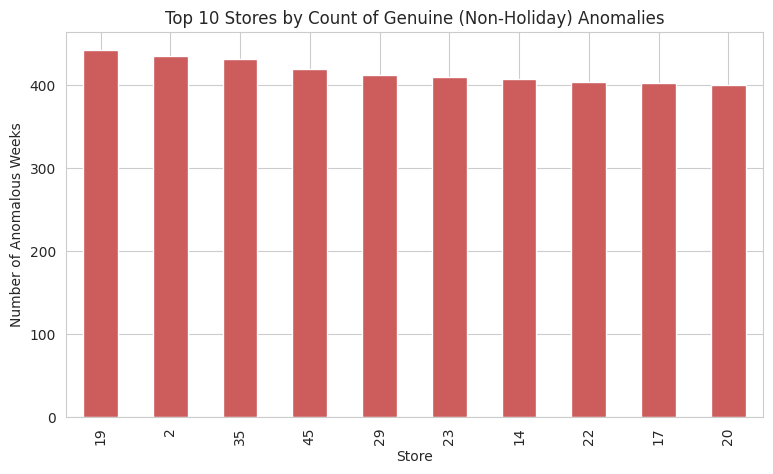

In [16]:
genuine_anomalies = df[(df['Anomaly_IQR']) & (df['IsHoliday']==False)]
print(f"Genuine (non-holiday) anomalies: {len(genuine_anomalies)} rows ({len(genuine_anomalies)/len(df):.2%} of data)")

top_stores_with_anomalies = genuine_anomalies.groupby('Store').size().sort_values(ascending=False).head(10)
plt.figure(figsize=(9,5))
top_stores_with_anomalies.plot(kind='bar', color='indianred')
plt.title('Top 10 Stores by Count of Genuine (Non-Holiday) Anomalies')
plt.ylabel('Number of Anomalous Weeks')
plt.xlabel('Store')
plt.show()

## 8. Save tagged dataset for downstream phases

In [17]:
df.to_csv(r'C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston Anomaly Detection\Anomaly tagged data output\anomaly_tagged_data.csv', index=False)
print("Saved anomaly_tagged_data.csv -", df.shape)

Saved anomaly_tagged_data.csv - (421570, 26)


## Conclusion - Phase 2

- Two complementary methods were used: **IQR** (per store-dept statistical outliers) and **Isolation Forest**
  (ML-based, context-aware outlier detection using relative deviation + holiday/markdown flags).
- IQR flagged **4.28%** of rows as unusual; only ~16% of those are holiday weeks - meaning the large majority
  are genuine, unexplained anomalies worth business investigation.
- Isolation Forest flagged **3.00%** of rows, but ~72% of those are holiday weeks - confirming that holiday
  spikes are so large they still look statistically unusual even when the model is told it's a holiday.
- **Business takeaway:** holiday-driven "anomalies" don't need action - they're expected and should be planned
  for (see Phase 1 EDA). The non-holiday anomalies (~3,600+ rows) are the real signal - these are the
  candidates for a closer look at store-level data quality, one-off local events, or stock-outs, and this
  tagged dataset (`Anomaly_IQR`, `Anomaly_IsoForest` columns) carries forward into the time-series and
  forecasting phases so these weeks can be handled deliberately rather than silently distorting the models.